In [12]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Number of customers:", df.shape[0])
print("Number of columns:", df.shape[1])
display(df.head())

Number of customers: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [13]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())

Data type: float64
Missing values: 11


In [14]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Number of input columns:", X.shape[1])
print("Customers who stayed:", (y == 0).sum())
print("Customers who left:", (y == 1).sum())

Number of input columns: 19
Customers who stayed: 5174
Customers who left: 1869


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

Training customers: 5634
Testing customers: 1409


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_cols = X_train.select_dtypes(include="number").columns
category_cols = X_train.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),
    ("category", OneHotEncoder(handle_unknown="ignore"), category_cols)
])

# Learn the median and categories from the training customers
X_train_ready = preprocessor.fit_transform(X_train)

# Apply those same rules to the test customers
X_test_ready = preprocessor.transform(X_test)

print("Training data:", X_train_ready.shape)
print("Testing data:", X_test_ready.shape)

Training data: (5634, 45)
Testing data: (1409, 45)


In [17]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=42
)

model.fit(X_train_ready, y_train)

print("Trees trained:", len(model.estimators_))
print(f"Out-of-bag accuracy: {model.oob_score_:.2%}")

Trees trained: 100
Out-of-bag accuracy: 78.86%


Test accuracy: 77.79%


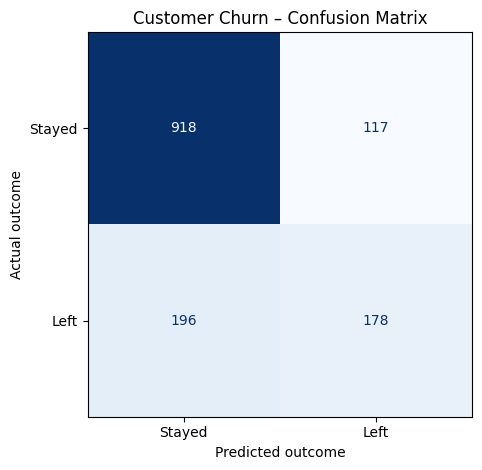

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# Predict whether each test customer stayed (0) or left (1)
y_pred = model.predict(X_test_ready)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=["Stayed", "Left"],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Customer Churn – Confusion Matrix")
plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.tight_layout()
plt.show()

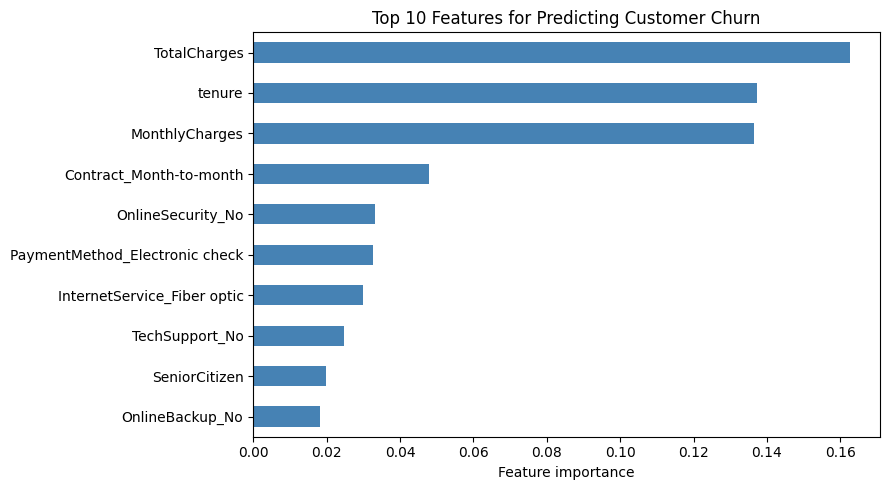

In [19]:
# Match each input column to its importance score
feature_names = preprocessor.get_feature_names_out()
importance = pd.Series(model.feature_importances_, index=feature_names)

# Remove column prefixes so the chart labels are easier to read
importance.index = importance.index.str.replace(
    r"^(numeric|category)__", "", regex=True
)

top_10 = importance.nlargest(10).sort_values()

ax = top_10.plot.barh(figsize=(9, 5), color="steelblue")
ax.set_title("Top 10 Features for Predicting Customer Churn")
ax.set_xlabel("Feature importance")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("churn_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
def predict_churn(customer):
    customer_ready = preprocessor.transform(customer)
    prediction = model.predict(customer_ready)[0]

    # In Step 3, we used 1 for a customer who left
    left_column = list(model.classes_).index(1)
    probability = model.predict_proba(customer_ready)[0, left_column]

    return "Left" if prediction == 1 else "Stayed", probability


# Double brackets keep the row in the same table format used for training
customer = X_test.iloc[[0]]
outcome, probability = predict_churn(customer)

display(customer[["tenure", "Contract", "MonthlyCharges"]])
print("Predicted outcome:", outcome)
print(f"Estimated chance of leaving: {probability:.1%}")
print("Actual outcome:", "Left" if y_test.iloc[0] == 1 else "Stayed")

,tenure,Contract,MonthlyCharges
437,72,Two year,114.05


Predicted outcome: Stayed
Estimated chance of leaving: 0.0%
Actual outcome: Stayed


In [21]:
from importlib.metadata import version
from google.colab import files

packages = ["pandas", "scikit-learn", "matplotlib"]

with open("requirements.txt", "w") as file:
    for package in packages:
        print(f"{package}=={version(package)}", file=file)

# Show the saved contents, then download the file
with open("requirements.txt") as file:
    print(file.read())

files.download("requirements.txt")

pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
sample = df.sample(n=100, random_state=42)
sample.to_csv("telco_churn_sample.csv", index=False)

print("Rows saved:", len(sample))
print(sample["Churn"].value_counts())
files.download("telco_churn_sample.csv")

Rows saved: 100
Churn
No     69
Yes    31
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>